# Tome S2, Chapter 10: Non-Euclidean geometry (Python companion)

Exercises first, solutions at the end. We measure spherical and hyperbolic triangles by Monte Carlo and compare with Girard and Gauss–Bonnet, check the distance formula against path lengths, build the triangle with angles $\frac\pi p,\frac\pi q,\frac\pi r$ for any admissible $p,q,r$, and watch the number of tiles grow exponentially. We use `numpy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math, cmath, random
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(10)

## Exercises

**P10.1 (★) Girard by Monte Carlo.** Pick random spherical triangles, compute their angles, and estimate their areas by sampling uniform points on the sphere. Compare with Theorem 10.1.

**P10.2 (★) Shortest paths.** In $\mathbb H$, compute the hyperbolic length of the h-line arc between two random points by numerical integration, compare with Theorem 10.6, and check that the straight Euclidean segment and random wiggly paths are longer.

**P10.3 (★★) Gauss–Bonnet by Monte Carlo.** In the disk model, pick random triangles, compute their angles, and estimate their hyperbolic areas with the area element $\frac{4\,dA}{(1-|w|^2)^2}$. Compare with Theorem 10.8.

**P10.4 (★★) Triangles $(p,q,r)$.** For integers with $\frac1p+\frac1q+\frac1r<1$, construct in the disk a triangle with angles $\frac\pi p,\frac\pi q,\frac\pi r$ by bisection (Exercise 10.10), and check its area.

**P10.5 (★★) Exponential growth.** Generate the $(2,3,7)$ tiling of Figure 10.3 by reflections and count the triangles whose centre lies within hyperbolic distance $\rho$ of $0$. Compare with $\frac{4\pi\sinh^2(\rho/2)}{\pi/42}$ (Exercise 10.6).

## Solutions

### P10.1
**How to find it.** The angle at $C$ comes from the tangent vectors of the proof of Proposition 10.2. A point $x$ of the sphere lies in the triangle when it is on the same side as the opposite vertex of each of the three planes through the sides.

In [2]:
def unit(v): return v / np.linalg.norm(v)
def sph_angle(C, A, B):
    tA, tB = A - (A @ C) * C, B - (B @ C) * C
    return math.acos(np.clip(unit(tA) @ unit(tB), -1, 1))
N = 400000
X = rng.normal(size=(N, 3)); X /= np.linalg.norm(X, axis=1)[:, None]
for trial in range(5):
    A, B, Cc = (unit(rng.normal(size=3)) for _ in range(3))
    inside = np.ones(N, bool)
    for P, Q, Rv in ((A, B, Cc), (B, Cc, A), (Cc, A, B)):
        n = np.cross(P, Q); inside &= np.sign(X @ n) == np.sign(Rv @ n)
    ang = sph_angle(A, B, Cc) + sph_angle(B, Cc, A) + sph_angle(Cc, A, B)
    print('angle sum - pi = %.4f   Monte Carlo area = %.4f' % (ang - math.pi, 4 * math.pi * inside.mean()))

angle sum - pi = 1.6900   Monte Carlo area = 1.6912
angle sum - pi = 1.4132   Monte Carlo area = 1.4206
angle sum - pi = 5.9350   Monte Carlo area = 5.9404
angle sum - pi = 0.9824   Monte Carlo area = 0.9830
angle sum - pi = 5.9474   Monte Carlo area = 5.9587


### P10.2
**How to find it.** Parametrise the arc of the half-circle by its angle and integrate $|dz|/y$; for other paths, sum $|\Delta z|/y$ over a fine polygon.

In [3]:
def hlen(path):
    z = np.asarray(path); mid = (z[1:] + z[:-1]) / 2
    return np.sum(np.abs(np.diff(z)) / mid.imag)
def dist(z, w): return math.acosh(1 + abs(z - w) ** 2 / (2 * z.imag * w.imag))
def hline_arc(z, w, n=20000):
    if abs(z.real - w.real) < 1e-12: return np.linspace(z, w, n)
    c = (abs(w) ** 2 - abs(z) ** 2) / (2 * (w.real - z.real))      # centre on the real axis
    t = np.linspace(cmath.phase(z - c), cmath.phase(w - c), n)
    return c + abs(z - c) * np.exp(1j * t)
for trial in range(4):
    z, w = complex(rng.uniform(-2, 2), rng.uniform(.2, 2)), complex(rng.uniform(-2, 2), rng.uniform(.2, 2))
    seg = np.linspace(z, w, 20000)
    wig = seg + 0.1j * np.sin(np.linspace(0, 7 * math.pi, 20000)) * np.sin(np.linspace(0, math.pi, 20000)) * min(z.imag, w.imag)
    print('formula %.5f   h-line arc %.5f   segment %.5f   wiggly %.5f' % (dist(z, w), hlen(hline_arc(z, w)), hlen(seg), hlen(wig)))

formula 1.65513   h-line arc 1.65513   segment 1.75140   wiggly 1.80741
formula 1.13299   h-line arc 1.13299   segment 1.13411   wiggly 1.14457
formula 1.76792   h-line arc 1.76792   segment 1.85504   wiggly 1.88566
formula 0.85466   h-line arc 0.85466   segment 0.85696   wiggly 0.96387


### P10.3
**How to find it.** In the disk, the isometry $\varphi_p(w)=\frac{w-p}{1-\bar pw}$ moves $p$ to $0$, where geodesics are diameters: the angle at $p$ is the angle between $\varphi_p(q)$ and $\varphi_p(r)$, and the geodesic from $p$ to $q$ is the image of a segment. A point $u$ lies inside the triangle when it is on the correct side of each of the three geodesics, which we test after moving one endpoint to $0$.

In [4]:
phi = lambda p, w: (w - p) / (1 - np.conj(p) * w)
def angle_at(p, q, r): return abs(cmath.phase(phi(p, r) / phi(p, q)))
def side(p, q, u):                        # sign of u relative to the geodesic through p, q (a diameter after phi_p)
    a = phi(p, q); return np.sign((np.conj(a) * phi(p, u)).imag)
M = 600000
U = np.sqrt(rng.uniform(0, 0.995 ** 2, M)) * np.exp(2j * math.pi * rng.uniform(size=M))   # uniform in the disk of radius .995
wgt = 4 / (1 - abs(U) ** 2) ** 2 * math.pi * 0.995 ** 2
for trial in range(5):
    T = [0.8 * math.sqrt(rng.uniform()) * cmath.exp(2j * math.pi * rng.uniform()) for _ in range(3)]
    p, q, r = T
    inside = (side(p, q, U) == side(p, q, r)) & (side(q, r, U) == side(q, r, p)) & (side(r, p, U) == side(r, p, q))
    angles = angle_at(p, q, r) + angle_at(q, r, p) + angle_at(r, p, q)
    print('pi - angle sum = %.4f   Monte Carlo area = %.4f' % (math.pi - angles, np.mean(inside * wgt)))

pi - angle sum = 0.2781   Monte Carlo area = 0.2813
pi - angle sum = 1.4070   Monte Carlo area = 1.4121
pi - angle sum = 0.1713   Monte Carlo area = 0.1721
pi - angle sum = 0.2441   Monte Carlo area = 0.2455
pi - angle sum = 0.4529   Monte Carlo area = 0.4603


### P10.4
**How to find it.** Put the angle $\frac\pi p$ at $0$, between the rays of arguments $0$ and $\frac\pi p$. Put $A=s>0$ on the real axis, and draw from $A$ the geodesic making the angle $\frac\pi q$ with the real axis; it meets the other ray at $B$. As $s$ grows from $0$, the angle at $B$ decreases from $\pi-\frac\pi p-\frac\pi q$ towards $0$; bisect on $s$ until it equals $\frac\pi r$. To draw the geodesic from $A$ in a given direction, move $A$ to $0$ with $\varphi_A$, where it is a diameter.

In [5]:
def triangle(p, q, r):
    def B_of(s):
        d = cmath.exp(1j * (math.pi - math.pi / q))          # direction of the side AB at A, after moving A to 0
        # points of the geodesic: phi_A^{-1}(t d), t in (0,1); find where its argument equals pi/p
        lo, hi = 0.0, 0.999999
        f = lambda t: cmath.phase((t * d + s) / (1 + s * t * d)) - math.pi / p
        if f(hi) < 0: return None
        for _ in range(80):
            mid = (lo + hi) / 2
            if f(mid) < 0: lo = mid
            else: hi = mid
        t = (lo + hi) / 2; return (t * d + s) / (1 + s * t * d)
    lo, hi = 1e-6, 0.999
    for _ in range(80):
        s = (lo + hi) / 2; B = B_of(s)
        if B is None or angle_at(B, 0j, s) < math.pi / r: hi = s
        else: lo = s
    s = (lo + hi) / 2; return 0j, complex(s), B_of(s)
for p, q, r in [(7, 2, 3), (4, 2, 5), (3, 3, 4), (5, 4, 3), (8, 8, 8)]:
    O, A, B = triangle(p, q, r)
    ang = (angle_at(O, A, B), angle_at(A, B, O), angle_at(B, O, A))
    print((p, q, r), 'angles x/pi =', [round(a / math.pi, 5) for a in ang], '  area/pi =', round((math.pi - sum(ang)) / math.pi, 5),
          '  expected', round(1 - 1 / p - 1 / q - 1 / r, 5))

(7, 2, 3) angles x/pi = [0.14286, 0.5, 0.33333]   area/pi = 0.02381   expected 0.02381
(4, 2, 5) angles x/pi = [0.25, 0.5, 0.2]   area/pi = 0.05   expected 0.05
(3, 3, 4) angles x/pi = [0.33333, 0.33333, 0.25]   area/pi = 0.08333   expected 0.08333
(5, 4, 3) angles x/pi = [0.2, 0.25, 0.33333]   area/pi = 0.21667   expected 0.21667
(8, 8, 8) angles x/pi = [0.125, 0.125, 0.125]   area/pi = 0.625   expected 0.625


### P10.5
**How to find it.** Reflect the triangle in its sides with the reflection of Exercise 10.5, transported to the disk: move one endpoint of the side to $0$, conjugate across the diameter, move back. Keep triangles whose centre is within distance $\rho_{\max}$.

rho = 1.0   triangles     42   area/(pi/42)        46
rho = 1.5   triangles    126   area/(pi/42)       114
rho = 2.0   triangles    224   area/(pi/42)       232
rho = 2.5   triangles    448   area/(pi/42)       431
rho = 3.0   triangles    770   area/(pi/42)       762
rho = 3.5   triangles   1302   area/(pi/42)      1308
rho = 4.0   triangles   2212   area/(pi/42)      2210
rho = 4.5   triangles   3696   area/(pi/42)      3697
rho = 5.0   triangles   6216   area/(pi/42)      6150
rho = 5.5   triangles  10150   area/(pi/42)     10193
rho = 6.0   triangles  16856   area/(pi/42)     16860
rho = 6.5   triangles  27706   area/(pi/42)     27852
rho = 7.0   triangles  45934   area/(pi/42)     45975


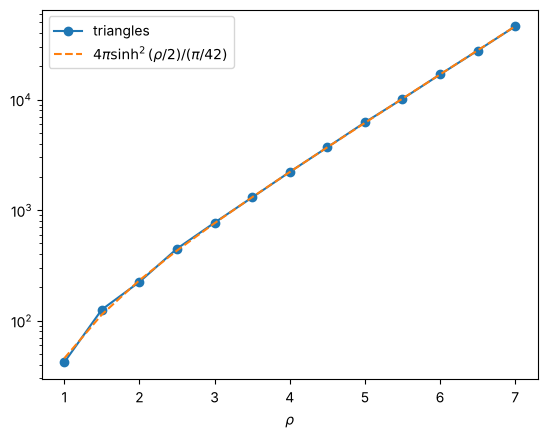

In [6]:
phiinv = lambda p, w: (w + p) / (1 + np.conj(p) * w)
def reflect(p, q, z):
    a = phi(p, q); u = a / abs(a)
    return phiinv(p, np.conj(phi(p, z) / u) * u)
def dist0(w): return 2 * math.atanh(abs(w))
O, A, B = triangle(7, 2, 3)
rho_max = 7.0
key = lambda t: tuple(np.round(np.array([sum(t) / 3]).view(float), 7))
seen = {key((O, A, B)): (O, A, B)}; frontier = [(O, A, B)]
while frontier:
    new = []
    for t in frontier:
        for i in range(3):
            p, q, r = t[i], t[(i + 1) % 3], t[(i + 2) % 3]
            nt = (p, q, reflect(p, q, r)); k = key(nt)
            if k in seen or dist0(sum(nt) / 3) > rho_max: continue
            seen[k] = nt; new.append(nt)
    frontier = new
centres = np.array([dist0(sum(t) / 3) for t in seen.values()])
rhos = np.arange(1, 7.01, 0.5)
counts = [np.sum(centres <= rho) for rho in rhos]
pred = [4 * math.pi * math.sinh(rho / 2) ** 2 / (math.pi / 42) for rho in rhos]
for rho, c, pr in zip(rhos, counts, pred): print('rho = %.1f   triangles %6d   area/(pi/42) %9.0f' % (rho, c, pr))
plt.semilogy(rhos, counts, 'o-', label='triangles'); plt.semilogy(rhos, pred, '--', label='$4\\pi\\sinh^2(\\rho/2)/(\\pi/42)$')
plt.xlabel('$\\rho$'); plt.legend(); plt.show()

The counts track the area of the hyperbolic disk, which grows like $e^{\rho}$: in the hyperbolic plane there is exponentially much room far away. That is why Escher's fish never run out of space,, and why trees embed so naturally in hyperbolic space.